# 02 — Similaridade, distância e clusterização

## Introdução

A pergunta que guia este notebook é a mesma do início do projeto:

> **Quais jogos apresentam perfis semelhantes de vendas e avaliação, e quais se afastam do padrão do mercado?**

Aqui ela é respondida **com a mineração**, antes de qualquer LLM: padronização
(Z-score) → distância Euclidiana → K-Means (cotovelo + silhouette) → perfil dos
grupos → resumo agregado para a etapa seguinte.

**O que este código faz**
- Importa `Path`, `json`, `warnings`, `numpy`, `pandas`, `matplotlib` e `seaborn`.
- Do scikit-learn: `StandardScaler` (Z-score), `NearestNeighbors` (distância),
  `KMeans` (agrupamento) e `silhouette_score` (qualidade dos grupos).
- `RNG = 42` fixa a semente aleatória → o resultado é reproduzível.
- `RAIZ` resolve o caminho da raiz do projeto.

**Não lê dados ainda** — apenas prepara o ambiente.

In [1]:
from pathlib import Path
import json, warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import NearestNeighbors
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50); pd.set_option("display.width", 170)
RNG = 42

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
print("Raiz:", RAIZ)


Raiz: /home/ivan/Ivan2.0/6°DSM/Mineracao/Porjeto_final


## 1. Carregar a base preparada (notebook 01)

**O que este código faz**
- Lê `data/processed/jogos_preparados.csv`, gerado no notebook 01.
- Define `ATRIBUTOS` com os **7 atributos** usados na modelagem.
- `df.dropna(subset=ATRIBUTOS)` garante que todos os 7 estão preenchidos (o notebook 01
  já fez isso; aqui é uma proteção) → **7.017 linhas**.
- `reset_index(drop=True)` renumera as linhas de 0 a 7.016, para casar com a matriz `X`.
- Mostra `Name`, `Platform`, `Genre` + os 7 atributos das primeiras linhas.

**Entra:** o CSV processado (22 colunas).
**Sai:** `base` (7.017 × 22) e `ATRIBUTOS` (lista de 7).
As colunas de identificação não entram no cálculo, só na descrição dos grupos.

In [2]:
df = pd.read_csv(RAIZ / "data" / "processed" / "jogos_preparados.csv")
print("Registros:", len(df))

ATRIBUTOS = ["NA_share", "EU_share", "JP_share", "Other_share",
             "log_global_sales", "Critic_Score", "User_Score"]
base = df.dropna(subset=ATRIBUTOS).reset_index(drop=True)
print("Base de modelagem:", base.shape)
base[["Name", "Platform", "Genre"] + ATRIBUTOS].head()


Registros: 7017
Base de modelagem: (7017, 22)


,Name,Platform,Genre,NA_share,EU_share,JP_share,Other_share,log_global_sales,Critic_Score,User_Score
0,Wii Sports,Wii,Sports,0.501090,0.350860,0.045675,0.102375,4.425206,76.0,8.0
1,Mario Kart Wii,Wii,Racing,0.441441,0.359234,0.106700,0.092624,3.597860,82.0,8.3
2,Wii Sports Resort,Wii,Sports,0.476350,0.333537,0.100092,0.090021,3.519573,80.0,8.0
3,New Super Mario Bros.,DS,Platform,0.378523,0.306711,0.218121,0.096644,3.427515,89.0,8.5
4,Wii Play,Wii,Misc,0.482878,0.317537,0.101349,0.098236,3.398527,58.0,6.6


## 2. Padronização Z-score

Os atributos têm escalas diferentes (shares 0–1, nota 0–100, log ~0–4). Sem padronizar,
a nota da crítica dominaria a distância. Z-score deixa todos com média 0 e desvio 1.

**O que este código faz**
- `base[ATRIBUTOS]` seleciona **apenas as 7 colunas numéricas** — as outras 15 ficam de fora.
- `StandardScaler().fit_transform(...)` aplica o **Z-score**: cada valor vira
  `(x − média) / desvio`. Resultado: média 0 e desvio 1 em cada atributo.
- Os dois `print` confirmam essa média e esse desvio.

**Por quê:** sem isso, `Critic_Score` (0–100) dominaria a distância e as shares (0–1)
quase não contariam.

**Sai:** `X`, uma matriz **7.017 × 7** padronizada.

In [3]:
X = StandardScaler().fit_transform(base[ATRIBUTOS])
print("Média por atributo (deve ser ~0):", X.mean(axis=0).round(3))
print("Desvio por atributo (deve ser ~1):", X.std(axis=0).round(3))


Média por atributo (deve ser ~0): [-0.  0. -0.  0.  0. -0.  0.]
Desvio por atributo (deve ser ~1): [1. 1. 1. 1. 1. 1. 1.]


## 3. Distância Euclidiana: pares mais semelhantes

Para evitar uma matriz 7.000 × 7.000 completa, usamos `NearestNeighbors` (mesma distância
Euclidiana, mas busca eficiente). Para cada jogo encontramos o vizinho mais próximo.

**O que este código faz, passo a passo**
1. `NearestNeighbors(...)` prepara a busca por distância **Euclidiana**.
2. `kneighbors(X)` devolve, para cada jogo, os 6 mais próximos (incluindo ele mesmo).
3. O bloco `mascara`/`primeiro` escolhe o **primeiro vizinho que não seja o próprio jogo**
   (importante quando dois jogos têm vetores idênticos).
4. Grava em `base` a distância e o nome/plataforma do vizinho.
5. Monta a tabela `pares` com jogo A ↔ jogo B.
6. Remove pares em que A = B e pares repetidos (A↔B e B↔A).
7. Conta quantos pares têm distância 0 (empate por arredondamento) e **exclui esses**
   da lista final, que mostra os **10 mais semelhantes com diferença real**.

**Entra:** `X` (7.017 × 7).
**Sai:** `pares` (10 linhas) e duas colunas novas em `base`.
Nenhuma coluna é descartada.

In [4]:
nn = NearestNeighbors(n_neighbors=6, metric="euclidean").fit(X)
dist, idx = nn.kneighbors(X)

# escolhe o vizinho mais proximo que NAO seja o proprio registro
pos = np.arange(len(X))
mascara = idx != pos[:, None]
primeiro = mascara.argmax(axis=1)
dist_vizinho = dist[pos, primeiro]
idx_vizinho = idx[pos, primeiro]

base["dist_vizinho"] = dist_vizinho
base["vizinho_nome"] = base.loc[idx_vizinho, "Name"].values
base["vizinho_plat"] = base.loc[idx_vizinho, "Platform"].values

pares = (base[["Name", "Platform", "vizinho_nome", "vizinho_plat", "dist_vizinho"]]
         .rename(columns={"Name": "jogo_a", "Platform": "plat_a",
                          "vizinho_nome": "jogo_b", "vizinho_plat": "plat_b"}))
pares = pares[pares["jogo_a"] != pares["jogo_b"]]
pares["chave"] = [tuple(sorted((a, b))) for a, b in zip(pares.jogo_a, pares.jogo_b)]
pares = (pares.sort_values("dist_vizinho")
               .drop_duplicates(subset=["chave"])
               .drop(columns="chave"))
identicos = int((pares["dist_vizinho"] <= 1e-9).sum())
print("Pares com perfil numericamente idêntico (distância 0):", identicos)
pares = pares[pares["dist_vizinho"] > 1e-9].head(10)
pares.round(4)


Pares com perfil numericamente idêntico (distância 0): 16


,jogo_a,plat_a,jogo_b,plat_b,dist_vizinho
2304,The SpongeBob SquarePants Movie,XB,Red Dead Revolver,XB,0.0143
2734,Primal,PS2,NFL Blitz 20-03,PS2,0.0154
2797,ESPN NHL 2K5,XB,SSX Tricky,XB,0.0155
3634,Fullmetal Alchemist 2: Curse of the Crimson El...,PS2,Legaia 2: Duel Saga,PS2,0.0174
4913,Blazing Angels 2: Secret Missions of WWII,X360,Divinity II: The Dragon Knight Saga,X360,0.0194
4895,Godzilla: Save the Earth,XB,X-Men: Next Dimension,GC,0.0194
5236,Cold Fear,PS2,Nightshade,PS2,0.0198
5373,Tom Clancy's Splinter Cell: Chaos Theory,GC,NHL Hitz 20-03,XB,0.0199
5631,LEGO Star Wars II: The Original Trilogy,GBA,WWE Crush Hour,GC,0.0203
5981,Alan Wake,PC,Torchlight,PC,0.0207


**Limitação importante:** alguns jogos ficam com distância 0 porque, em vendas muito baixas,
os valores são arredondados para 2 casas e várias combinações colapsam no mesmo vetor.
Por isso, para o relatório, mostramos os pares mais semelhantes **com distância maior que zero**
(diferenças reais) e registramos essa limitação na conclusão.

## 4. Registros mais atípicos

Um jogo "fora do padrão" é aquele cuja média de distância aos 10 vizinhos mais próximos
é alta — ele não se parece com ninguém. Também mostramos a distância ao centróide global.

**O que este código faz**
- Busca os **12 vizinhos** mais próximos de cada jogo (10 + ele mesmo + folga).
- Para cada jogo, descarta ele mesmo e calcula a **média das distâncias aos 10 mais próximos**.
- `dist_centroide` mede a distância do jogo ao "centro" de todos os dados.
- Ordena do maior para o menor e mostra os **10 mais atípicos**, com vendas, notas e as duas distâncias.

**Interpretação:** distância média alta = o jogo não se parece com ninguém.
**Sai:** `atipicos` (10 linhas) e duas colunas novas em `base`.

In [5]:
k_atip = 10
nn10 = NearestNeighbors(n_neighbors=k_atip + 2, metric="euclidean").fit(X)
d10, i10 = nn10.kneighbors(X)
pos = np.arange(len(X))
# remove o proprio jogo e usa os k_atip vizinhos mais proximos
medias = []
for linha in range(len(X)):
    ds = d10[linha][i10[linha] != linha][:k_atip]
    medias.append(ds.mean())
base["dist_media_10nn"] = medias
base["dist_centroide"] = np.linalg.norm(X - X.mean(axis=0), axis=1)

atipicos = (base.sort_values("dist_media_10nn", ascending=False)
            [["Name", "Platform", "Genre", "Global_Sales", "Critic_Score", "User_Score",
              "dist_media_10nn", "dist_centroide"]]
            .head(10))
atipicos.round(3)


,Name,Platform,Genre,Global_Sales,Critic_Score,User_Score,dist_media_10nn,dist_centroide
11,Grand Theft Auto: San Andreas,PS2,Action,20.81,95.0,9.0,4.239,8.630
30,Gran Turismo 4,PS2,Racing,11.66,89.0,8.5,3.623,9.306
1175,Guitar Hero 5,PS2,Misc,1.12,71.0,2.6,3.309,6.450
1126,Sonic the Hedgehog,PS3,Platform,1.16,43.0,4.1,2.863,7.337
3445,The Sims 2: Pets,PS2,Simulation,0.30,68.0,8.0,2.772,11.421
0,Wii Sports,Wii,Sports,82.53,76.0,8.0,2.770,8.872
103,Final Fantasy XII,PS2,Role-Playing,5.95,92.0,7.6,2.769,5.203
2390,The Golden Compass,PS2,Action,0.52,46.0,5.2,2.696,9.553
185,Metal Gear Solid 3: Snake Eater,PS2,Action,4.23,91.0,9.3,2.688,6.355
2031,Okami,PS2,Action,0.63,93.0,9.3,2.683,6.891


## 5. Escolha de k: cotovelo (WCSS) + silhouette

Testamos k de 2 a 10. O **cotovelo** mostra onde a queda de inércia desacelera;
o **silhouette** mede coesão interna vs separação entre grupos (quanto maior, melhor).

**O que este código faz**
- Testa **k de 2 a 10**.
- Para cada k: cria um K-Means, agrupa e guarda duas métricas:
  - `inércia` (WCSS): soma das distâncias ao centróide — quanto menor, mais compacto;
  - `silhouette`: coesão interna × separação entre grupos — quanto maior, melhor.
- Monta a tabela `metricas` com uma linha por k.

**Entra:** `X`.
**Sai:** `metricas` (9 linhas × 3 colunas) e as listas `inercia`/`silhueta`.
Nenhum dado é alterado.

In [6]:
ks = list(range(2, 11))
inercia, silhueta = [], []
for k in ks:
    km = KMeans(n_clusters=k, random_state=RNG, n_init=10)
    rot = km.fit_predict(X)
    inercia.append(km.inertia_)
    silhueta.append(silhouette_score(X, rot))
    print(f"k={k:2d} | inércia={km.inertia_:10.1f} | silhouette={silhueta[-1]:.4f}")

metricas = pd.DataFrame({"k": ks, "inercia": inercia, "silhouette": silhueta})
metricas.round(4)


k= 2 | inércia=   39752.6 | silhouette=0.1934


k= 3 | inércia=   33041.7 | silhouette=0.2348


k= 4 | inércia=   27947.7 | silhouette=0.2318


k= 5 | inércia=   23763.8 | silhouette=0.2461


k= 6 | inércia=   20740.9 | silhouette=0.2526


k= 7 | inércia=   19292.0 | silhouette=0.2462


k= 8 | inércia=   17815.8 | silhouette=0.2420


k= 9 | inércia=   16803.4 | silhouette=0.2221


k=10 | inércia=   15732.3 | silhouette=0.2393


,k,inercia,silhouette
0,2,39752.6112,0.1934
1,3,33041.7096,0.2348
2,4,27947.7330,0.2318
3,5,23763.7834,0.2461
4,6,20740.9152,0.2526
5,7,19291.9665,0.2462
6,8,17815.7545,0.2420
7,9,16803.4285,0.2221
8,10,15732.3411,0.2393


**O que este código faz**
- Desenha dois gráficos lado a lado: inércia × k (método do cotovelo) e silhouette × k.

**Só visualização** — não altera nada.

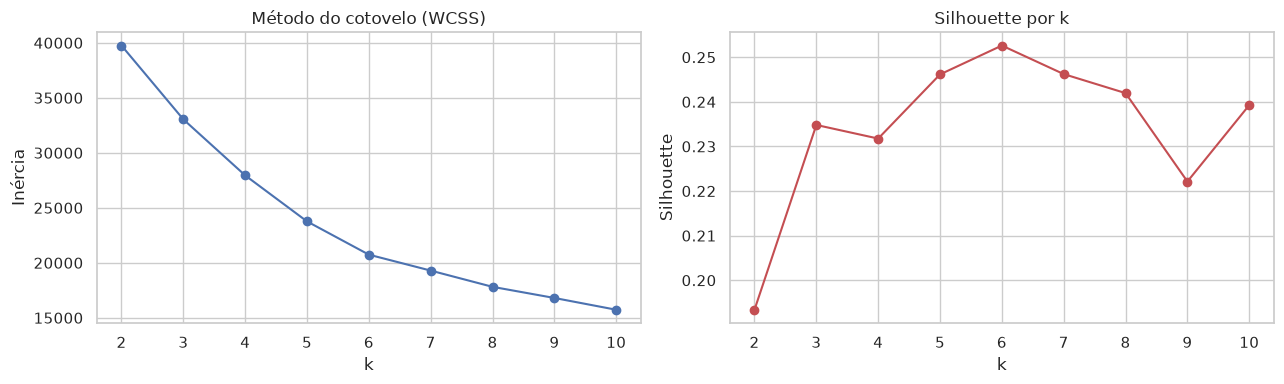

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(ks, inercia, "o-", color="#4C72B0")
axes[0].set(title="Método do cotovelo (WCSS)", xlabel="k", ylabel="Inércia")
axes[1].plot(ks, silhueta, "o-", color="#C44E52")
axes[1].set(title="Silhouette por k", xlabel="k", ylabel="Silhouette")
plt.tight_layout(); plt.show()


### Escolha automática de k

Adotamos o k que maximiza o silhouette (empate → menor k). Assim a decisão é guiada
pelos dados, não pelo desejo de obter um número específico de grupos.

**O que este código faz**
- `idxmax()` encontra a linha com **maior silhouette**; `K` recebe o k correspondente.
- Treina o K-Means final com esse `K`.
- `fit_predict` devolve o grupo de cada jogo e grava em `base["cluster"]`.
- Mostra quantos jogos há em cada grupo.

**Entra:** `X` e `metricas`.
**Sai:** `K` (o número escolhido) e a coluna `cluster` em `base`.

In [8]:
K = int(metricas.loc[metricas["silhouette"].idxmax(), "k"])
print("k escolhido:", K)

km = KMeans(n_clusters=K, random_state=RNG, n_init=10)
base["cluster"] = km.fit_predict(X)
print(base["cluster"].value_counts().sort_index().to_string())


k escolhido: 6


cluster
0    1101
1     557
2     865
3    2022
4     607
5    1865


## 6. Perfil dos grupos (em escala original)

Traduzimos os centróides padronizados de volta para valores interpretáveis e
agregamos gênero/plataforma dominantes.

**O que este código faz**
- `groupby("cluster")` + `agg` calcula, por grupo: tamanho, vendas médias, crítica média,
  usuário médio e as 4 shares médias.
- `pct` converte o tamanho em percentual do total.
- `top_categoria` pega os 2 gêneros e as 2 plataformas mais frequentes de cada grupo.

**Entra:** `base` com a coluna `cluster`.
**Sai:** `perfil`, uma tabela com **6 linhas** (uma por grupo) e 11 colunas.

In [9]:
perfil = (base.groupby("cluster")
          .agg(n=("Name", "size"),
               vendas_medias=("Global_Sales", "mean"),
               critica_media=("Critic_Score", "mean"),
               usuario_medio=("User_Score", "mean"),
               na=("NA_share", "mean"), eu=("EU_share", "mean"),
               jp=("JP_share", "mean"), outros=("Other_share", "mean"))
          .round(3))
perfil["pct"] = (perfil["n"] / perfil["n"].sum() * 100).round(1)

def top_categoria(g, col, n=1):
    return ", ".join(g[col].value_counts().head(n).index)

perfil["genero_top"] = [top_categoria(base[base.cluster == c], "Genre", 2) for c in perfil.index]
perfil["plataforma_top"] = [top_categoria(base[base.cluster == c], "Platform", 2) for c in perfil.index]
perfil


,n,vendas_medias,critica_media,usuario_medio,na,eu,jp,outros,pct,genero_top,plataforma_top
cluster,,,,,,,,,,,
0,1101,0.280,49.498,5.027,0.697,0.207,0.015,0.080,15.7,"Action, Shooter","X360, Wii"
1,557,0.487,71.372,7.755,0.234,0.103,0.616,0.047,7.9,"Role-Playing, Action","PS2, PS3"
2,865,3.590,83.434,7.801,0.524,0.311,0.064,0.102,12.3,"Action, Shooter","PS2, X360"
3,2022,0.322,72.908,7.735,0.790,0.142,0.019,0.048,28.8,"Sports, Action","XB, GC"
4,607,0.149,74.473,7.093,0.036,0.880,0.005,0.079,8.7,"Action, Strategy","PC, PS4"
5,1865,0.513,71.795,7.427,0.439,0.393,0.025,0.143,26.6,"Action, Shooter","PS2, PS3"


**O que este código faz**
- Dois gráficos de barras: crítica média por grupo e vendas médias por grupo.

**Só visualização.**

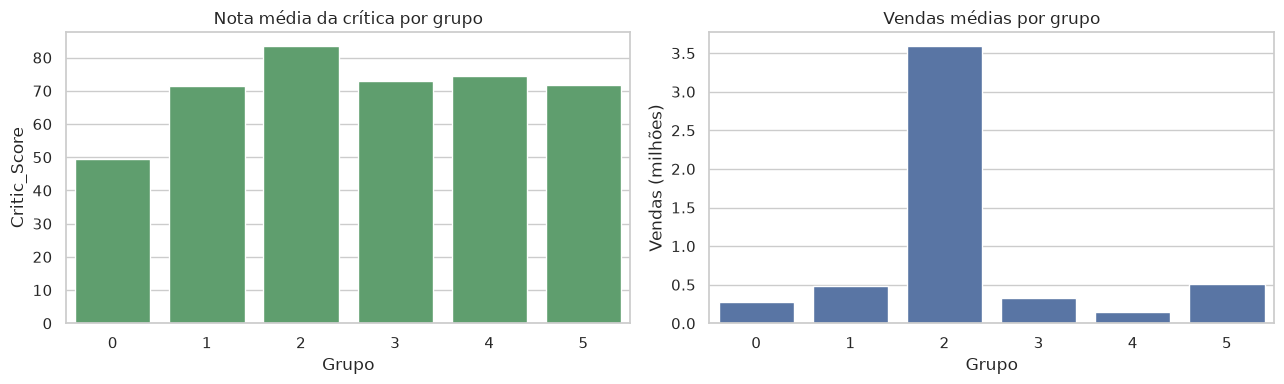

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.barplot(x=perfil.index, y="critica_media", data=perfil, ax=axes[0], color="#55A868")
axes[0].set(title="Nota média da crítica por grupo", xlabel="Grupo", ylabel="Critic_Score")
sns.barplot(x=perfil.index, y="vendas_medias", data=perfil, ax=axes[1], color="#4C72B0")
axes[1].set(title="Vendas médias por grupo", xlabel="Grupo", ylabel="Vendas (milhões)")
plt.tight_layout(); plt.show()


## 7. Grupos de exemplo: o jogo mais típico de cada grupo

Para dar nome aos grupos, vemos os jogos mais próximos de cada centróide.

**O que este código faz**
- Para cada grupo, calcula a distância de cada jogo ao **centróide** do grupo.
- Ordena e pega os **3 mais próximos** (os mais "típicos" do grupo).
- Junta tudo em uma tabela.

**Entra:** `X`, `base` e `km.cluster_centers_`.
**Sai:** tabela com 3 jogos por grupo (18 linhas).

In [11]:
tipicos = []
for c in range(K):
    grupo = base[base.cluster == c].copy()
    d = np.linalg.norm(X[grupo.index] - km.cluster_centers_[c], axis=1)
    top = grupo.iloc[np.argsort(d)[:3]][["Name", "Platform", "Global_Sales", "Critic_Score", "User_Score"]]
    top.insert(0, "cluster", c)
    tipicos.append(top)
pd.concat(tipicos).round(2)


,cluster,Name,Platform,Global_Sales,Critic_Score,User_Score
3897,0,X-Men: Destiny,X360,0.24,47.0,5.0
3878,0,Dreamcast Collection,X360,0.24,53.0,5.2
4181,0,Disney's Planes,WiiU,0.20,51.0,5.3
2602,1,Final Fantasy Crystal Chronicles: Echoes of Time,DS,0.47,75.0,7.3
3533,1,Tales of Phantasia,GBA,0.29,76.0,8.1
2512,1,Dragon Ball Z: Supersonic Warriors 2,DS,0.49,66.0,7.6
426,2,Pure,X360,2.47,85.0,7.7
367,2,Killzone 3,PS3,2.77,84.0,7.9
394,2,Skate 3,X360,2.63,80.0,8.0
4056,3,Shrek SuperSlam,GC,0.22,70.0,7.8


## 8. Resumo agregado para a LLM

**Este é o único conteúdo que vai para a API.** Nada de CSV bruto: apenas números
agregados, nomes de jogos públicos e estatísticas. Sem dados pessoais.

**O que este código faz**
- Monta um dicionário `resumo` com **apenas resultados agregados**: dataset, pergunta,
  nº de registros, atributos usados, método, k e silhouette.
- Para cada grupo: tamanho, %, médias, shares, gêneros/plataformas predominantes e exemplos.
- Adiciona os 10 pares mais semelhantes e os 10 atípicos.
- `write_text(json.dumps(...))` salva em `saidas/resumo_analise.json`.
- O `print` final mostra o começo do JSON.

**O que NÃO vai para o resumo:** o CSV, as 7.017 linhas individuais e qualquer dado
pessoal (que não existe na base). Vão só números agregados e nomes públicos de jogos.
**Sai:** `saidas/resumo_analise.json` — a única entrada do notebook 03.

In [12]:
resumo = {
    "dataset": "Video Game Sales with Ratings (VGChartz + Metacritic)",
    "pergunta": "Quais jogos apresentam perfis semelhantes de vendas e avaliação, e quais se afastam do padrão do mercado?",
    "registros_analisados": int(len(base)),
    "atributos_usados": ATRIBUTOS,
    "metodo": "Z-score + distância Euclidiana + K-Means",
    "k_escolhido": int(K),
    "silhouette": round(float(metricas.loc[metricas.k == K, "silhouette"].iloc[0]), 4),
    "grupos": [],
    "pares_mais_semelhantes": [],
    "pares_com_perfil_identico_arredondamento": identicos,
    "jogos_mais_atipicos": [],
}

for c in perfil.index:
    p = perfil.loc[c]
    g = base[base.cluster == c]
    resumo["grupos"].append({
        "grupo": int(c),
        "registros": int(p["n"]),
        "percentual": float(p["pct"]),
        "vendas_medias_milhoes": round(float(p["vendas_medias"]), 3),
        "critica_media_0_100": round(float(p["critica_media"]), 2),
        "usuario_medio_0_10": round(float(p["usuario_medio"]), 2),
        "share_NA": round(float(p["na"]), 3),
        "share_EU": round(float(p["eu"]), 3),
        "share_JP": round(float(p["jp"]), 3),
        "share_Outros": round(float(p["outros"]), 3),
        "generos_predominantes": g["Genre"].value_counts().head(3).index.tolist(),
        "plataformas_predominantes": g["Platform"].value_counts().head(3).index.tolist(),
        "exemplos": g.nlargest(3, "Global_Sales")["Name"].tolist(),
    })

for _, r in pares.iterrows():
    resumo["pares_mais_semelhantes"].append({
        "jogo_a": r["jogo_a"], "plataforma_a": r["plat_a"],
        "jogo_b": r["jogo_b"], "plataforma_b": r["plat_b"],
        "distancia": round(float(r["dist_vizinho"]), 4),
    })

for _, r in atipicos.iterrows():
    resumo["jogos_mais_atipicos"].append({
        "jogo": r["Name"], "plataforma": r["Platform"], "genero": r["Genre"],
        "vendas_globais": float(r["Global_Sales"]),
        "critica": None if pd.isna(r["Critic_Score"]) else float(r["Critic_Score"]),
        "usuario": None if pd.isna(r["User_Score"]) else float(r["User_Score"]),
        "dist_media_10_vizinhos": round(float(r["dist_media_10nn"]), 4),
    })

saida = RAIZ / "saidas" / "resumo_analise.json"
saida.write_text(json.dumps(resumo, ensure_ascii=False, indent=2), encoding="utf-8")
print("Resumo salvo em:", saida)
print(json.dumps(resumo, ensure_ascii=False, indent=2)[:1500])


Resumo salvo em: /home/ivan/Ivan2.0/6°DSM/Mineracao/Porjeto_final/saidas/resumo_analise.json
{
  "dataset": "Video Game Sales with Ratings (VGChartz + Metacritic)",
  "pergunta": "Quais jogos apresentam perfis semelhantes de vendas e avaliação, e quais se afastam do padrão do mercado?",
  "registros_analisados": 7017,
  "atributos_usados": [
    "NA_share",
    "EU_share",
    "JP_share",
    "Other_share",
    "log_global_sales",
    "Critic_Score",
    "User_Score"
  ],
  "metodo": "Z-score + distância Euclidiana + K-Means",
  "k_escolhido": 6,
  "silhouette": 0.2526,
  "grupos": [
    {
      "grupo": 0,
      "registros": 1101,
      "percentual": 15.7,
      "vendas_medias_milhoes": 0.28,
      "critica_media_0_100": 49.5,
      "usuario_medio_0_10": 5.03,
      "share_NA": 0.697,
      "share_EU": 0.207,
      "share_JP": 0.015,
      "share_Outros": 0.08,
      "generos_predominantes": [
        "Action",
        "Shooter",
        "Sports"
      ],
      "plataformas_predominan

## 9. Conclusões objetivas desta etapa

- k escolhido pelos dados (silhouette), não imposto.
- O silhouette fica em torno de **0,25**, o que indica estrutura de grupos **fraca/moderada**:
  os perfis se sobrepõem, como é comum em dados de mercado. Isso é uma **limitação honesta**,
  não um erro — os grupos são úteis de forma descritiva, mas não são separáveis com
  fronteiras rígidas. Vale discutir na conclusão crítica.
- Cada grupo tem perfil de vendas/região/notas distinto.
- Existem pares praticamente idênticos (mesmo perfil) e jogos isolados (atípicos).
- **Vendas e avaliação não caminham sempre juntas** — isso aparece nos centróides.

O resumo em `saidas/resumo_analise.json` é a **única entrada** do notebook 03 (LLM).
